# Домашнее задание

In [1]:
# Импортируем библиотеки

import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
data = pd.read_csv('500_Person_Gender_Height_Weight_Index.csv')

In [3]:
# Удаляем ненужный столбец
data.drop('Index', axis = 1, inplace = True)
data.head()

,Gender,Height,Weight
0,Male,174,96
1,Male,189,87
2,Female,185,110
3,Female,195,104
4,Male,149,61


In [4]:
data.shape

(500, 3)

## 1. Создайте колонку BMI (индекс массы тела), которая считается по формуле: BMI = (Вес в кг) / (Рост в метрах)^2. Учтите, что ваш текущий рост в см, не метры.

In [6]:
data['BMI'] = data['Weight'] / (data['Height'] / 100) ** 2


In [7]:
data.head()

,Gender,Height,Weight,BMI
0,Male,174,96,31.708284
1,Male,189,87,24.355421
2,Female,185,110,32.140248
3,Female,195,104,27.350427
4,Male,149,61,27.476240


## 2. Посчитайте среднее значение, медиану, и моду для роста, веса, BMI.

In [9]:
print("Среднее:")
print(data[['Height', 'Weight', 'BMI']].mean())

Среднее:
Height    169.944000
Weight    106.000000
BMI        37.765284
dtype: float64


In [10]:
print("\nМедиана:")
print(data[['Height', 'Weight', 'BMI']].median())


Медиана:
Height    170.500000
Weight    106.000000
BMI        36.956941
dtype: float64


In [11]:
print("\nМода:")
print(data[['Height', 'Weight', 'BMI']].mode().iloc[0])


Мода:
Height    188.00000
Weight     50.00000
BMI        37.34559
Name: 0, dtype: float64


## 3. Найдите range (диапазон, т.е. макс - мин), и стандартное отклонение для роста, веса, BMI. И расскажите что это означает.

In [42]:
# Среднее значение
mean_height = data['Height'].mean()
mean_weight = data['Weight'].mean()
mean_bmi = data['BMI'].mean()
print(f"Среднее:\n  Рост: {mean_height:.2f} см\n  Вес: {mean_weight:.2f} кг\n  BMI: {mean_bmi:.2f}")

Среднее:
  Рост: 169.94 см
  Вес: 106.00 кг
  BMI: 37.77


In [43]:
# Медиана
median_height = data['Height'].median()
median_weight = data['Weight'].median()
median_bmi = data['BMI'].median()
print(f"Медиана:\n  Рост: {median_height:.2f} см\n  Вес: {median_weight:.2f} кг\n  BMI: {median_bmi:.2f}")

Медиана:
  Рост: 170.50 см
  Вес: 106.00 кг
  BMI: 36.96


In [44]:
# Мода
mode_height = data['Height'].mode()[0]
mode_weight = data['Weight'].mode()[0]
mode_bmi = data['BMI'].mode()[0]
print(f"Мода:\n  Рост: {mode_height} см\n  Вес: {mode_weight} кг\n  BMI: {mode_bmi:.2f}")

Мода:
  Рост: 188 см
  Вес: 50 кг
  BMI: 37.35


In [ ]:
# Средние, медианные и модальные значения для роста, веса и BMI:

- Средний рост: 169.944 см
- Средний вес: 106.0 кг
- Средний BMI: 37.77
- Медианный рост: 170.5 см
- Медианный вес: 106.0 кг
- Медианный BMI: 36.96
- Мода для роста: 188 см
- Мода для веса: 50 кг
- Мода для BMI: 37.35 

## 4. Найдите 15-й процентиль и 90-й процентиль для роста, веса, BMI. Что это означает простыми словами?

In [45]:
print("15-й процентиль:")
print(data[['Height', 'Weight', 'BMI']].quantile(0.15))

15-й процентиль:
Height    150.000000
Weight     67.000000
BMI        22.761869
Name: 0.15, dtype: float64


In [46]:
print("\n90-й процентиль:")
print(data[['Height', 'Weight', 'BMI']].quantile(0.90))


90-й процентиль:
Height    191.000000
Weight    150.100000
BMI        57.703274
Name: 0.9, dtype: float64


In [ ]:
# 15% людей имеют значения ниже 15-го процентиля, и 90% — ниже 90-го процентиля.

## 5. Создайте гистограмму для роста, веса, BMI.

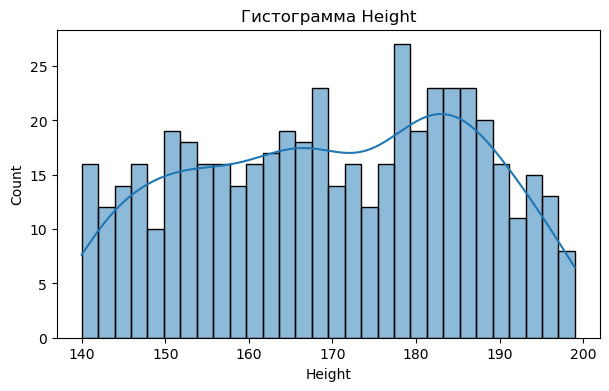

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

features = ['Height']

for feature in features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data[feature], kde=True, bins=30)
    plt.title(f'Гистограмма {feature}')
    plt.show()


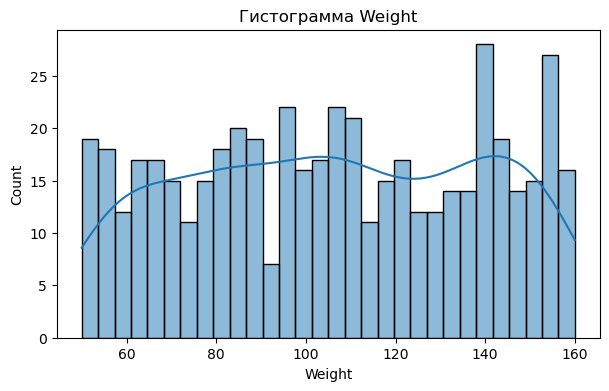

In [22]:
features = ['Weight']

for feature in features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data[feature], kde=True, bins=30)
    plt.title(f'Гистограмма {feature}')
    plt.show()

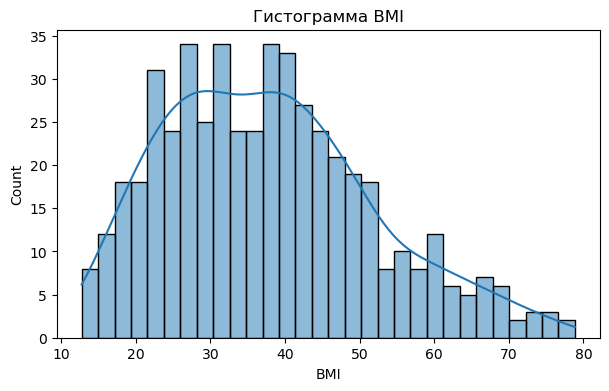

In [23]:
features = ['BMI']

for feature in features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data[feature], kde=True, bins=30)
    plt.title(f'Гистограмма {feature}')
    plt.show()

## 6. Создайте box plot для роста, веса, BMI в разрезе пола. Что вы видите, опишите?

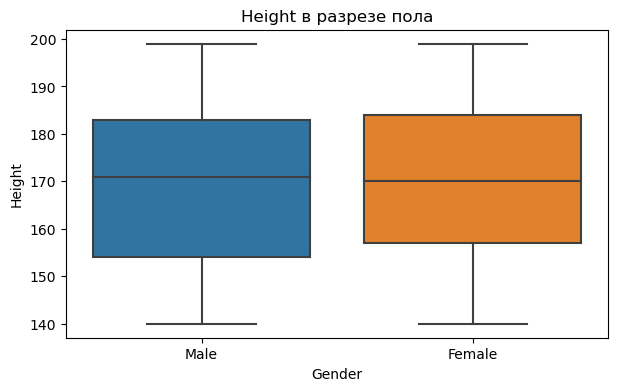

In [26]:
for feature in features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x='Gender', y=feature, data=data)
    plt.title(f'{feature} в разрезе пола')
    plt.show()


In [ ]:
# Мы видим разницу в росте, весе и BMI между мужчинами и женщинами, а также наличие выбросов (точки вне усов).

## 7. Посчитайте межквартильный размах для роста, веса, BMI.

In [33]:
Q1 = data[['Height']].quantile(0.25)
Q3 = data[['Height']].quantile(0.75)
IQR = Q3 - Q1

print("Межквартильный размах:")
print(IQR)

Межквартильный размах:
Height    28.0
dtype: float64


In [34]:
Q1 = data[['Weight']].quantile(0.25)
Q3 = data[['Weight']].quantile(0.75)
IQR = Q3 - Q1

print("Межквартильный размах:")
print(IQR)


Межквартильный размах:
Weight    56.0
dtype: float64


In [35]:
Q1 = data[['BMI']].quantile(0.25)
Q3 = data[['BMI']].quantile(0.75)
IQR = Q3 - Q1

print("Межквартильный размах:")
print(IQR)

Межквартильный размах:
BMI    19.221115
dtype: float64


## 8. Есть ли в данных какие-то выбросы для роста, веса, BMI? Как можно их найти? Используя межквартильный размах? Удалите все такие выбросы из таблицы.

In [50]:
# Логическая маска
mask = ~(
    (data[['Height', 'Weight', 'BMI']] < (Q1 - 1.5 * IQR)) |
    (data[['Height', 'Weight', 'BMI']] > (Q3 + 1.5 * IQR))
).any(axis=1)

data_cleaned = data[mask]

print(f"Удалено выбросов: {len(data) - len(data_cleaned)}")


Удалено выбросов: 3


/var/folders/h5/nn_z0fbd4099gxgkjqyqmtvr0000gn/T/ipykernel_48843/247213271.py:3: FutureWarning: Automatic reindexing on DataFrame vs Series comparisons is deprecated and will raise ValueError in a future version. Do `left, right = left.align(right, axis=1, copy=False)` before e.g. `left == right`
  (data[['Height', 'Weight', 'BMI']] < (Q1 - 1.5 * IQR)) |
/var/folders/h5/nn_z0fbd4099gxgkjqyqmtvr0000gn/T/ipykernel_48843/247213271.py:4: FutureWarning: Automatic reindexing on DataFrame vs Series comparisons is deprecated and will raise ValueError in a future version. Do `left, right = left.align(right, axis=1, copy=False)` before e.g. `left == right`
  (data[['Height', 'Weight', 'BMI']] > (Q3 + 1.5 * IQR))


______________________________